# Qiskit · Quantum Africa: Moroccan crop challenge

Build a quantum or hybrid classifier for **alfalfa, maize and wheat**. Read the [student brief (PDF)](../Student_Challenge_Brief.pdf) and [installation instructions](../README.md), select your project Python kernel, then run the cells in order. All data is supplied: **914 training, 150 validation and 221 unlabeled test fields**. “Development data” means validation data.

**Your challenge:** the simple QNN currently performs worse than the classical baseline (mean validation macro-F1 **0.8557 versus 0.8797**). Improve it **or replace it with another quantum or hybrid approach**; you are not required to build on this QNN. Compare fairly and explain your findings.

The workflow is load → preprocess → fit → evaluate → investigate. The default quick fit uses 100 fixed training fields; change `USE_FULL_TRAINING` to `True` for all 914. Later plots use supplied full-training results, independently of your quick fit. The final section maps each Python file to the changes you can make.

**Data assumption:** crop labels surveyed on 23–27 April 2024 are assumed valid for imagery from 25 April (±2 calendar days); crop persistence is not independently verified. See [data notes](../data/README.md) for feature definitions and spatial splits. Keep evaluation fields fixed and use validation, never test labels, to choose settings.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Find the supplied package whether you open this notebook from the root or notebooks/.
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'challenge/coverage.py').exists(), 'Run from the repository root or its notebooks folder'
sys.path.insert(0, str(ROOT))
from challenge.data import load_data
from challenge.coverage import LABELS
from challenge.classical import reference
from challenge.models import QuantumClassifier, MatchedHead
from challenge.metrics import score

# Figures and your quick-run results are saved here; supplied results stay unchanged.
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
def save_show(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=160, bbox_inches='tight')
    display(fig)
    plt.close(fig)

# Verify checksums, feature schemas and split IDs, then load the tables and prepared view.
tables, view, manifest, _ = load_data()
USE_FULL_TRAINING = False  # Change to True for the main 914-field comparison.
train, validation = tables['train'], tables['validation']
features = manifest['features']
assert LABELS == ['alfalfa', 'maize', 'wheat']
assert 'target' not in tables['test']
print('Classes:', LABELS)
print('Rows:', manifest['rows'])
print('Python:', sys.version.split()[0])

Classes: ['alfalfa', 'maize', 'wheat']
Rows: {'train': 914, 'validation': 150, 'test': 221}
Python: 3.12.16


## 1. Prepare inputs and inspect the data

`features` selects the 13 numerical bands/NDVI columns, excluding IDs and labels. `prep` standardizes them, reduces them to four PCA components, then standardizes those components. `A` is the training representation; `B` is validation transformed using the same fitted pipeline. No transform is fitted on validation or test.

For this quick walkthrough, preprocessing uses all 914 training fields and the models fit the fixed 100-field subset (34 alfalfa, 33 maize, 33 wheat). For a strict training-size experiment, use the coverage commands below: they refit preprocessing using only the selected subset.

**Read the plots:** the left panel shows class imbalance; the right shows the first two training-fitted components, not geographic locations. Overlap suggests that these two components alone do not separate all crops. You can replace the representation here, but update both QNN and control consistently; the current model expects four inputs.

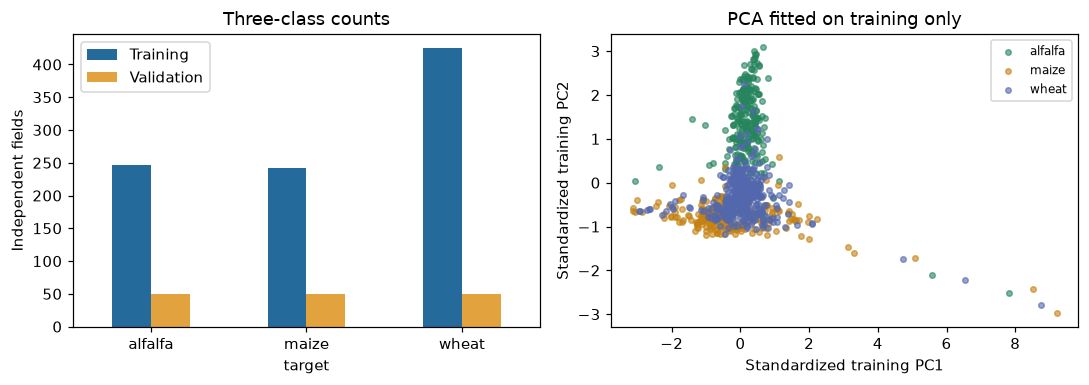

In [2]:
# Fit on training features only; reuse this object unchanged for evaluation.
prep = make_pipeline(StandardScaler(), PCA(4, svd_solver='full'), StandardScaler())
A = prep.fit_transform(train[features].to_numpy())
B = prep.transform(validation[features].to_numpy())
# Select exactly the same training fields for all three models.
starter_ids = json.loads((ROOT / 'data/starter_ids.json').read_text())
starter = train.set_index('sample_id').loc[starter_ids]
index = train.set_index('sample_id').index.get_indexer(starter_ids)
assert len(index) == 100 and (index >= 0).all()
assert set(starter.target) == set(LABELS)
if USE_FULL_TRAINING:
    index = np.arange(len(train))
    starter = train

# Inspect imbalance and the feature view before interpreting classifier scores.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
counts = pd.DataFrame({'Training': train.target.value_counts(),
                       'Validation': validation.target.value_counts()}).reindex(LABELS)
counts.plot.bar(ax=axes[0], rot=0, color=['#246a9a','#e2a33e'])
axes[0].set(ylabel='Independent fields', title='Three-class counts')
for label, color in zip(LABELS, ['#26855d','#c48214','#5267ad']):
    mask = train.target.eq(label).to_numpy()
    axes[1].scatter(A[mask, 0], A[mask, 1], label=label, s=13, alpha=.6, color=color)
axes[1].set(xlabel='Standardized training PC1', ylabel='Standardized training PC2', title='PCA fitted on training only')
axes[1].legend(fontsize=8)
fig.tight_layout(); save_show(fig, '01_data_overview')
counts.to_csv(OUT / 'class_counts.csv')

## 2. Understand or replace the model

Four prepared features become angles `(π/2) × (1 + tanh(x))`. Four RY encoding gates feed one `real_amplitudes` repetition with eight trainable angles. `QMLSampler(shots=None)` gives exact probabilities. **Outcome modulo 3** maps all 16 bitstrings into class groups of **6/5/5**, in `LABELS` order; no outcome is discarded.

The classical control is 4 → tanh(1) → softmax(3), with 11 trainable values. Its **37.5% parameter mismatch** is a limitation to report. Both branches use the same inputs and 100 COBYLA objective evaluations. Shared preprocessing stores 99 fitted coefficients; complete fitted totals are 107 (QNN) and 110 (control), counting shared values once.

**Read the outputs:** the flow diagram traces data to probabilities; the circuit distinguishes input `x` from trainable `theta`. The resource dictionary reports four qubits, depth six and three CX gates before routing. Objective evaluations are zero before fitting. Change `encoding` or `max_evals` below for a first experiment; change `make_circuit` in `challenge/models.py` for architecture changes. Keep the baseline and comparable control.

The next cell fits seed 0, checks probability normalization, row-order independence and save/reload consistency, then reports **quick-run validation** scores. Macro-F1 averages the three class F1 scores equally; accuracy counts correct fields; recall lists follow `LABELS`. Passing assertions produce no output; a failed assertion stops the cell.

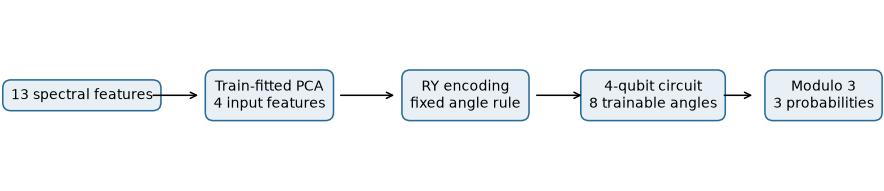

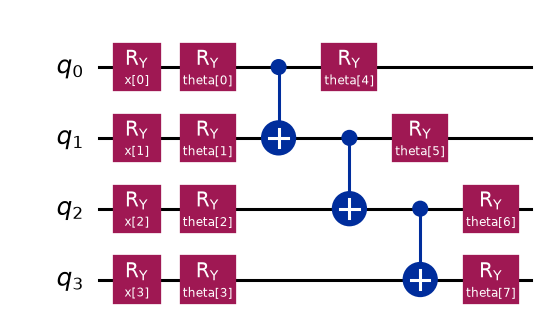

{'qubits': 4, 'trainable': 8, 'frozen_quantum': 0, 'depth': 6, 'two_qubit_gates': 3, 'objective_evaluations': 0, 'readout_group_sizes': [6, 5, 5], 'encoding': 'ry', 'compilation': 'logical decomposed H/P/RY/CX; no backend routing'}


In [3]:
# Diagram of the starter pipeline; update its labels if you replace the model.
fig, ax = plt.subplots(figsize=(10, 2))
ax.axis('off')
boxes = [(0.08, '13 spectral features'), (.30, 'Train-fitted PCA\n4 input features'),
         (.53, 'RY encoding\nfixed angle rule'), (.75, '4-qubit circuit\n8 trainable angles'),
         (.95, 'Modulo 3\n3 probabilities')]
for x, label in boxes:
    ax.text(x, .5, label, transform=ax.transAxes, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=.6', fc='#e8f0f5', ec='#246a9a'))
for (x, _), (next_x, _) in zip(boxes[:-1], boxes[1:]):
    ax.annotate('', xy=(next_x-.08,.5), xytext=(x+.08,.5), xycoords='axes fraction', arrowprops={'arrowstyle':'->'})
save_show(fig, '02_model_flow')
# Student controls: try encoding='zz' or a different evaluation budget, then rerun below.
qnn = QuantumClassifier(LABELS, encoding='ry', max_evals=100)
save_show(qnn.circuit.draw(output='mpl', fold=-1), '03_actual_circuit')
print(qnn.resources())

In [4]:
# Fit both heads on identical rows. Change seed=0 to 1 and 2 for your final comparisons.
qnn.fit(A[index], starter.target.to_numpy(), seed=0)
control = MatchedHead(LABELS, max_evals=100).fit(A[index], starter.target.to_numpy(), seed=0)
# Columns must be alfalfa, maize, wheat; exact probabilities should agree with Statevector.
prob = qnn.predict_proba(B[:6])
assert prob.shape == (6, 3) and np.allclose(prob.sum(axis=1), 1)
np.testing.assert_allclose(prob, [qnn.ideal_proba(row) for row in B[:6]], atol=1e-12)
np.testing.assert_array_equal(qnn.predict(B[:6][::-1])[::-1], qnn.predict(B[:6]))
# Check that saving and loading preserves predictions. Adapt this if you replace the model.
from qiskit_machine_learning.algorithms import NeuralNetworkClassifier
qnn.model.to_dill(str(OUT / 'starter_qnn.dill'))
loaded = NeuralNetworkClassifier.from_dill(str(OUT / 'starter_qnn.dill'))
from challenge.models import angles
np.testing.assert_allclose(prob, loaded.neural_network.forward(angles(B[:6]), loaded.weights))
# The classical baseline uses all 13 features, but the same selected training rows.
classical = reference().fit(train.iloc[index][features].to_numpy(), starter.target.to_numpy())
print('Classical quick-run:', score(validation.target, classical.predict(validation[features].to_numpy()), LABELS))
# These are scores from the fit above, not the supplied full-training benchmark.
starter_scores = {name: score(validation.target, model.predict(B), LABELS)
                  for name, model in [('qnn', qnn), ('control', control)]}
(OUT / 'starter_scores.json').write_text(json.dumps(starter_scores, indent=2))
display(pd.DataFrame(starter_scores).loc[['macro_f1', 'accuracy', 'recall']])

Classical quick-run: {'macro_f1': 0.8590686274509803, 'accuracy': 0.86, 'precision': [0.8846153846153846, 0.8461538461538461, 0.8478260869565217], 'recall': [0.92, 0.88, 0.78], 'support': [50, 50, 50], 'confusion': [[46, 1, 3], [2, 44, 4], [4, 7, 39]]}


,qnn,control
macro_f1,0.852769,0.574326
accuracy,0.853333,0.626667
recall,"[0.94, 0.88, 0.74]","[0.86, 0.88, 0.14]"


## 3. Interpret the supplied full-training results

These plots read saved **914-field training / 150-field validation** predictions and histories from `results/`; they do not retrain or reflect edits to your quick fit. RBF-SVM (`C=100`, `gamma=0.01`) is the fixed classical baseline and is deterministic. The QNN/control use seeds 0, 1 and 2.

- **Convergence:** lower training cross-entropy is better, but does not guarantee better validation performance. Evaluation count and elapsed seconds show different costs. QNN loss is converted from bits to natural-log units (nats) to match the control. The SVM has no comparable iterative loss curve here.
- **Confusion matrices:** rows are true crops, columns are predictions. Diagonal percentages are class recall; counts remain visible. Both panels share a 0–1 scale and use seed 0.
- **Performance and runtime:** dots are individual seeds; bars show mean macro-F1 ± population standard deviation (`ddof=0`), not a confidence interval over new fields. Runtime includes preprocessing, fit and prediction and uses a log scale. The table reports branch resources; shared preprocessing is described above.

The QNN has lower average validation accuracy (**85.56%**) than the baseline (**88.00%**). Use this as your starting comparison, not evidence of quantum advantage. To plot your own benchmark, save it separately and adapt the file paths below; preserve the supplied results.

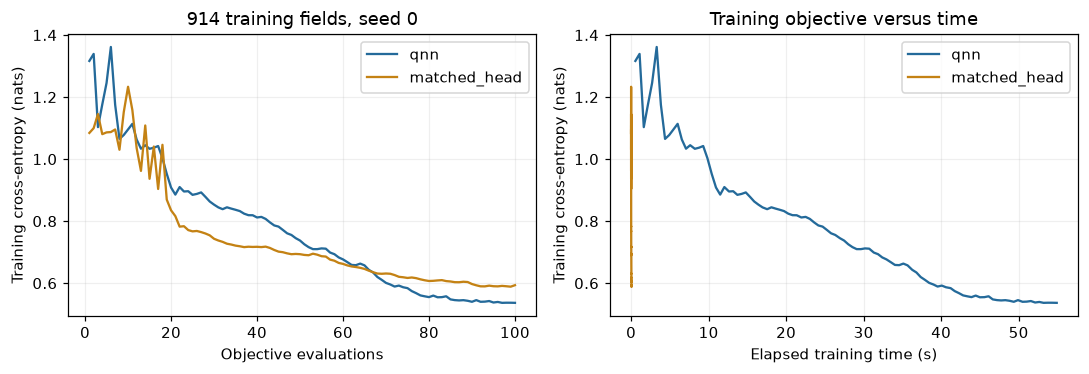

In [5]:
# Saved seed-0 training histories: objective versus evaluation count and wall time.
runs = json.loads((ROOT / 'results/runs.json').read_text())
summary = json.loads((ROOT / 'results/summary.json').read_text())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, color in [('qnn', '#246a9a'), ('matched_head', '#c48214')]:
    h = pd.DataFrame(json.loads((ROOT / f'results/{name}_0_history.json').read_text()))
    # Qiskit uses log2; the control uses natural log. Plot both in nats.
    if name == 'qnn': h['objective'] *= np.log(2)
    axes[0].plot(h.evaluation, h.objective, label=name, color=color)
    axes[1].plot(h.seconds, h.objective, label=name, color=color)
for ax in axes:
    ax.set_ylabel('Training cross-entropy (nats)'); ax.legend(); ax.grid(alpha=.2)
axes[0].set(xlabel='Objective evaluations', title='914 training fields, seed 0')
axes[1].set(xlabel='Elapsed training time (s)', title='Training objective versus time')
fig.tight_layout(); save_show(fig, '04_convergence')

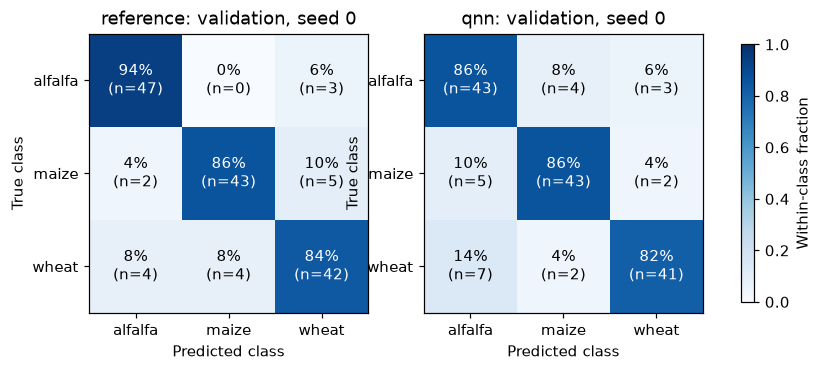

In [6]:
# Recompute both confusion matrices from saved validation predictions in the same class order.
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, ['reference', 'qnn']):
    p = pd.read_csv(ROOT / f'results/{name}_0_predictions.csv')
    cm = confusion_matrix(p.target, p.prediction, labels=LABELS)
    normalized = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(normalized, vmin=0, vmax=1, cmap='Blues')
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{normalized[i,j]:.0%}\n(n={cm[i,j]})', ha='center', va='center',
                    color='white' if normalized[i,j] > .55 else 'black')
    ax.set(xticks=range(3), yticks=range(3), xticklabels=LABELS, yticklabels=LABELS,
           xlabel='Predicted class', ylabel='True class', title=f'{name}: validation, seed 0')
fig.colorbar(im, ax=axes.tolist(), label='Within-class fraction', shrink=.8)
save_show(fig, '05_confusion')

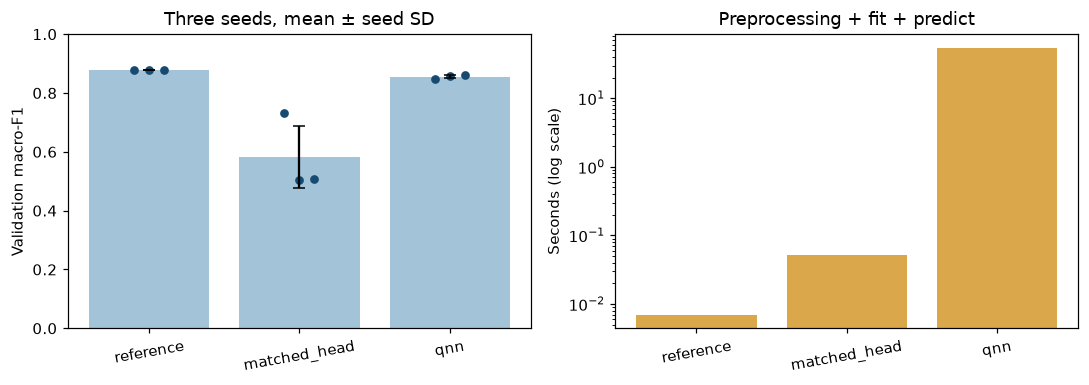

,model,mean_fit_predict_seconds,trainable,objective_evaluations,qubits,frozen_quantum,depth,two_qubit_gates,readout_group_sizes,encoding,compilation
0,reference,0.006906,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,matched_head,0.051146,11.0,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,qnn,54.927574,8.0,100.0,4.0,0.0,6.0,3.0,"[6, 5, 5]",ry,logical decomposed H/P/RY/CX; no backend routing


In [7]:
# Compare all three seeds; np.std() uses ddof=0 for these supplied summaries.
models = ['reference', 'matched_head', 'qnn']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
resource_rows = []
for x, model in enumerate(models):
    selected = [r for r in runs if r['model']==model]
    f1 = np.array([r['metrics']['macro_f1'] for r in selected])
    seconds = np.array([r['fit_seconds']+r['predict_seconds']+r['preprocessing_seconds'] for r in selected])
    axes[0].bar(x, f1.mean(), yerr=f1.std(), color='#a2c3d8', capsize=4)
    axes[0].scatter(x+np.linspace(-.1,.1,3), f1, color='#164a70', s=22)
    axes[1].bar(x, seconds.mean(), color='#dba74b')
    resource_rows.append({'model':model, **selected[0]['resources'], 'mean_fit_predict_seconds':seconds.mean()})
for ax in axes: ax.set_xticks(range(3), models, rotation=10)
axes[0].set(ylabel='Validation macro-F1', ylim=(0,1), title='Three seeds, mean ± seed SD')
axes[1].set(ylabel='Seconds (log scale)', yscale='log', title='Preprocessing + fit + predict')
fig.tight_layout(); save_show(fig, '06_performance_runtime')
resources = pd.DataFrame(resource_rows)
display(resources)
resources.to_csv(OUT / 'resources.csv', index=False)

## 4. Increase training coverage carefully

Use the same validation/test sets and all three classes. From a terminal in the repository root:

```bash
.venv/bin/python -m challenge.coverage check
.venv/bin/python -m challenge.coverage train --size 600 --results outputs/size600
.venv/bin/python -m challenge.coverage train --size 914 --results outputs/size914
.venv/bin/python -m challenge.coverage compare --baseline outputs/size600 --candidate outputs/size914
```

The training commands fit preprocessing on their selected rows, run seeds 0/1/2 and save validation scores, predictions and histories. Use `--size 100` or `200` for smaller checks. `comparison.json` reports changes in macro-F1, accuracy and each crop's recall, with paired spatial-bootstrap lower bounds. A bound below zero leaves possible loss unresolved; seed variation is a separate quantity.

**Beyond 914 fields:** request a checked extension preserving crop definitions, ±2-day dates and spatial independence. Do not duplicate rows, import unchecked source records or move evaluation fields into training. After receiving its `train.csv` and manifest:

```bash
.venv/bin/python -m challenge.coverage check --extension-dir /path/to/extension
.venv/bin/python -m challenge.coverage train --extension-dir /path/to/extension --results outputs/extended
.venv/bin/python -m challenge.coverage compare --baseline outputs/size914 --candidate outputs/extended
```

The source's >10,000 records span other crops, dates, regions and repeated observations; they are not all eligible fields. **More data does not guarantee better accuracy.** Inspect all classes, document any loss and freeze settings before final test prediction. See [coverage details](../docs/COVERAGE.md).

In [8]:
# Fast integrity check; success prints counts and file_checks="passed".
# The longer training commands above are optional and are not run by this cell.
import subprocess
subprocess.run([sys.executable, '-m', 'challenge.coverage', 'check'], cwd=ROOT, check=True)
learning = json.loads((ROOT / 'results/learning_curve_summary.json').read_text())

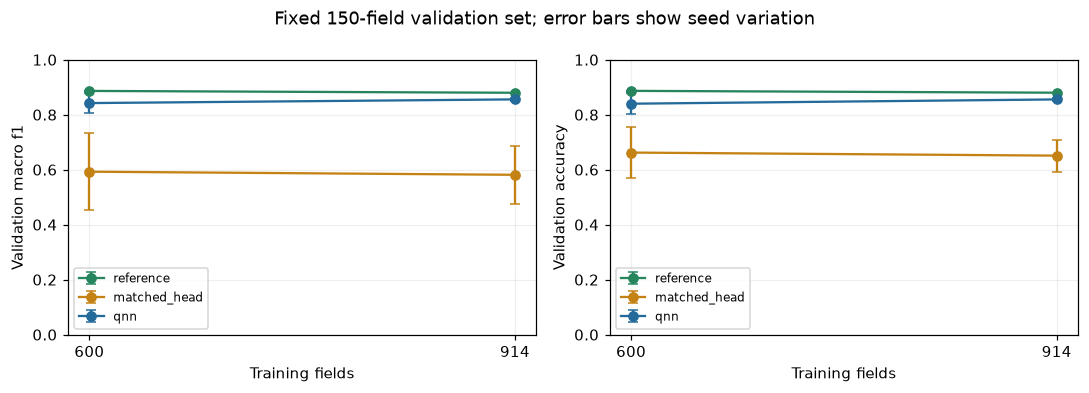

9275

In [9]:
# Plot the supplied size comparison on the identical 150 validation fields.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sizes = [600, 914]
for model, color in zip(models, ['#26855d','#c48214','#246a9a']):
    rows = [next(r for r in learning['metrics'] if r['train']==size and r['model']==model)
            for size in sizes]
    for ax, metric in zip(axes, ['macro_f1','accuracy']):
        ax.errorbar(sizes, [r[metric+'_mean'] for r in rows],
                    yerr=[r[metric+'_sd'] for r in rows], marker='o', label=model, color=color, capsize=3)
        ax.set(xlabel='Training fields', ylabel='Validation '+metric.replace('_',' '), ylim=(0,1), xticks=sizes)
        ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle('Fixed 150-field validation set; error bars show seed variation')
fig.tight_layout(); save_show(fig, '07_expansion')
(OUT / 'expansion_summary.json').write_text(json.dumps(learning, indent=2))

**Read the learning curve:** from 600 to 914 fields, mean QNN macro-F1 rises from 0.8422 to 0.8557, while baseline macro-F1 falls slightly from 0.8865 to 0.8797. More training fields do not help every model. Error bars show three-seed variation, not confidence over new fields; inspect per-class recall before concluding that coverage helped.

For your next experiment, change one factor (encoding, depth, representation or training size), keep comparisons fair, and explain the result. You may instead build a quantum kernel or another hybrid. For stacking supervised model predictions, generate training predictions out of fold before fitting the combining model. See [method ideas](../docs/HINTS.md) and [evaluation requirements](../docs/EVALUATION.md).

## 5. Our solution: an 8-qubit quantum kernel, judged against a matched classical control

**Focused question:** does the entangling part of a quantum feature map add predictive value beyond a classical RBF kernel that sees the same inputs?

**Model** ([`challenge/qkernel.py`](../challenge/qkernel.py)): 13 spectral features → StandardScaler → PCA(8) → StandardScaler (fit on training rows only) → 8-qubit feature map `H · RZ(2a·xᵢ) · RZZ(2γ·xᵢxᵢ₊₁)` on a linear chain → fidelity kernel `K(x,x') = |⟨ψ(x)|ψ(x')⟩|²` from exact Qiskit statevectors → SVM with a precomputed kernel. The circuit has **no trainable angles**; `a` (bandwidth) and `γ` (entangling strength) are chosen on validation. Feature-map family: Havlíček et al. (2019).

**Controls:** (1) the same circuit with every RZZ removed (γ = 0, a product state whose kernel is ∏cos²(a·Δx)); (2) a **matched RBF-SVM** on the same 8 prepared inputs; (3) the supplied reference RBF-SVM on the 13 raw features.

**Fair tuning:** 80 quantum configurations (5 a × 4 γ × 4 C) vs 80 RBF configurations (20 γ × 4 C), one selection rule (best validation macro-F1, then accuracy, then smallest C). Every model is deterministic, so seeds 0/1/2 give identical predictions (checked in code; SD = 0). Differences use a paired spatial-block bootstrap over the 18 supplied validation blocks (2000 resamples).

`RERUN_STUDY=0` in the environment reuses the stored results in `outputs/qk/`; otherwise the next cell reruns the full study (a few minutes on a laptop CPU).

Selected quantum kernel: {'a': 0.2, 'gamma': 0.01, 'reps': 1, 'C': 100} | matched RBF: {'gamma': 0.11288, 'C': 10}
Tuning: {'quantum_configs': 80, 'rbf_configs': 80, 'quantum_seconds': 46.02891580000005, 'rbf_seconds': 3.738186399999904, 'rule': 'max validation macro-F1, then accuracy, then smallest C'}


,macro_f1,accuracy,precision_alfalfa,recall_alfalfa,precision_maize,recall_maize,precision_wheat,recall_wheat,fit_s,predict_150_s
model,,,,,,,,,,
quantum_kernel,0.9400 ± 0.0000,0.9400 ± 0.0000,0.960,0.96,0.940,0.94,0.920,0.92,2.717,0.513
no_entanglement,0.9400 ± 0.0000,0.9400 ± 0.0000,0.980,0.96,0.923,0.96,0.918,0.90,2.689,0.538
matched_rbf,0.9323 ± 0.0000,0.9333 ± 0.0000,0.960,0.96,0.893,1.00,0.955,0.84,0.068,0.013
reference,0.8797 ± 0.0000,0.8800 ± 0.0000,0.887,0.94,0.915,0.86,0.840,0.84,0.056,0.011


C:\Users\pc\AppData\Local\Temp\ipykernel_4936\1109484500.py:23: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame({x['model']: x['resources'] for x in s['runs'] if x['seed'] == 0}).fillna('–'))


,quantum_kernel,no_entanglement,matched_rbf,reference
qubits,8,8,0.0,–
logical_depth,9,2,–,–
rzz_gates,7,0,–,–
trainable_circuit_parameters,0,0,–,–
svm_dual_coefficients,380,378,466.0,434.0
svm_intercepts,3,3,3.0,–
support_vectors,190,189,233.0,217.0
encoder_fitted_values,159,159,159.0,–
kernel_matrix_floats,835396,835396,0.0,–
statevector_simulations,1064,1064,0.0,–


,macro_f1,macro_f1_ci,accuracy,accuracy_ci,fields_differing
quantum_kernel - reference,0.06026,"[0.025581, 0.108714]",0.06,"[0.026316, 0.100946]",13
matched_rbf - reference,0.052598,"[0.019488, 0.09107]",0.053333,"[0.021855, 0.090294]",11
quantum_kernel - matched_rbf,0.007662,"[-0.026058, 0.044881]",0.006667,"[-0.023813, 0.039614]",7
no_entanglement - quantum_kernel,-0.000012,"[-0.002045, 0.00294]",0.0,"[0.0, 0.0]",2


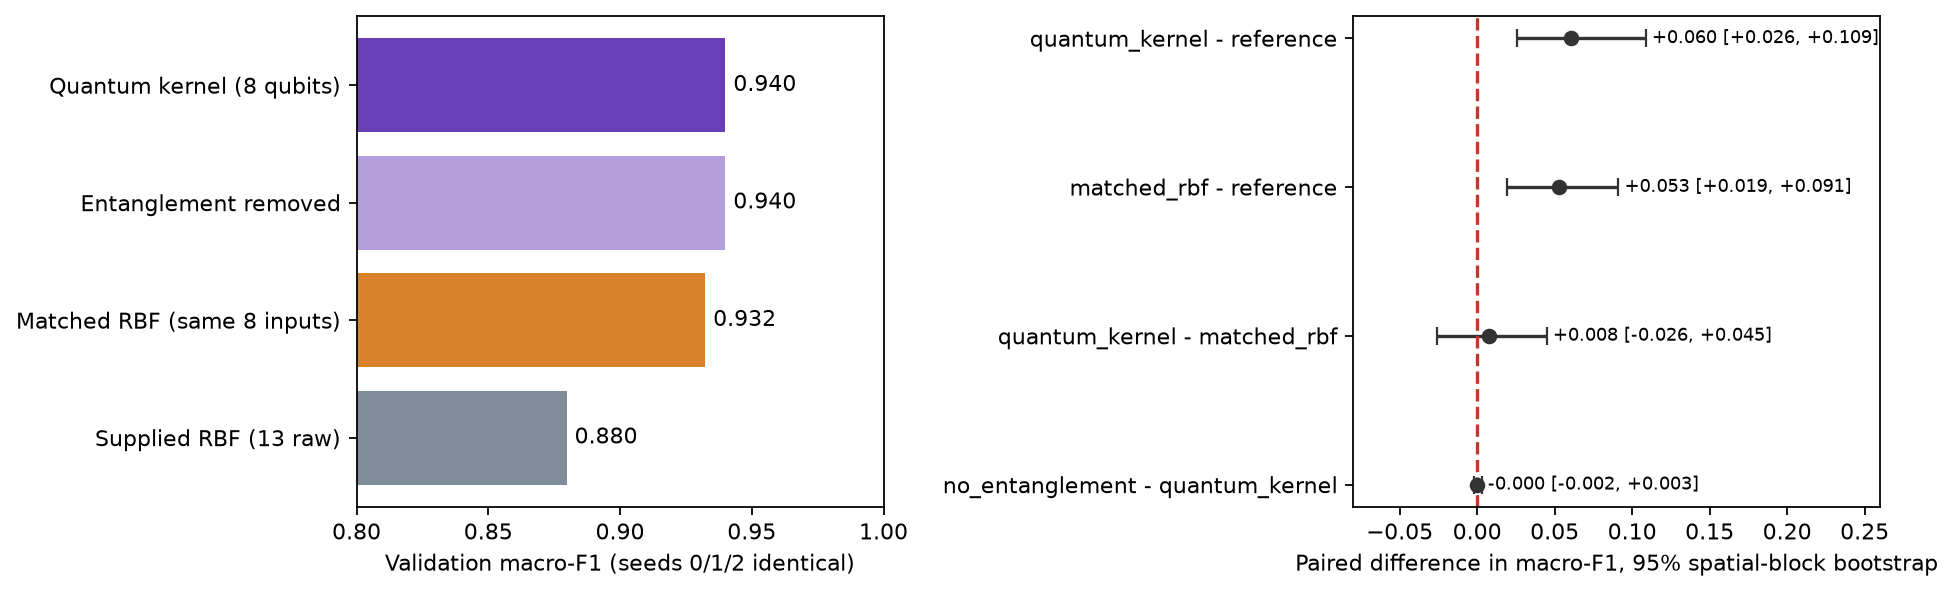

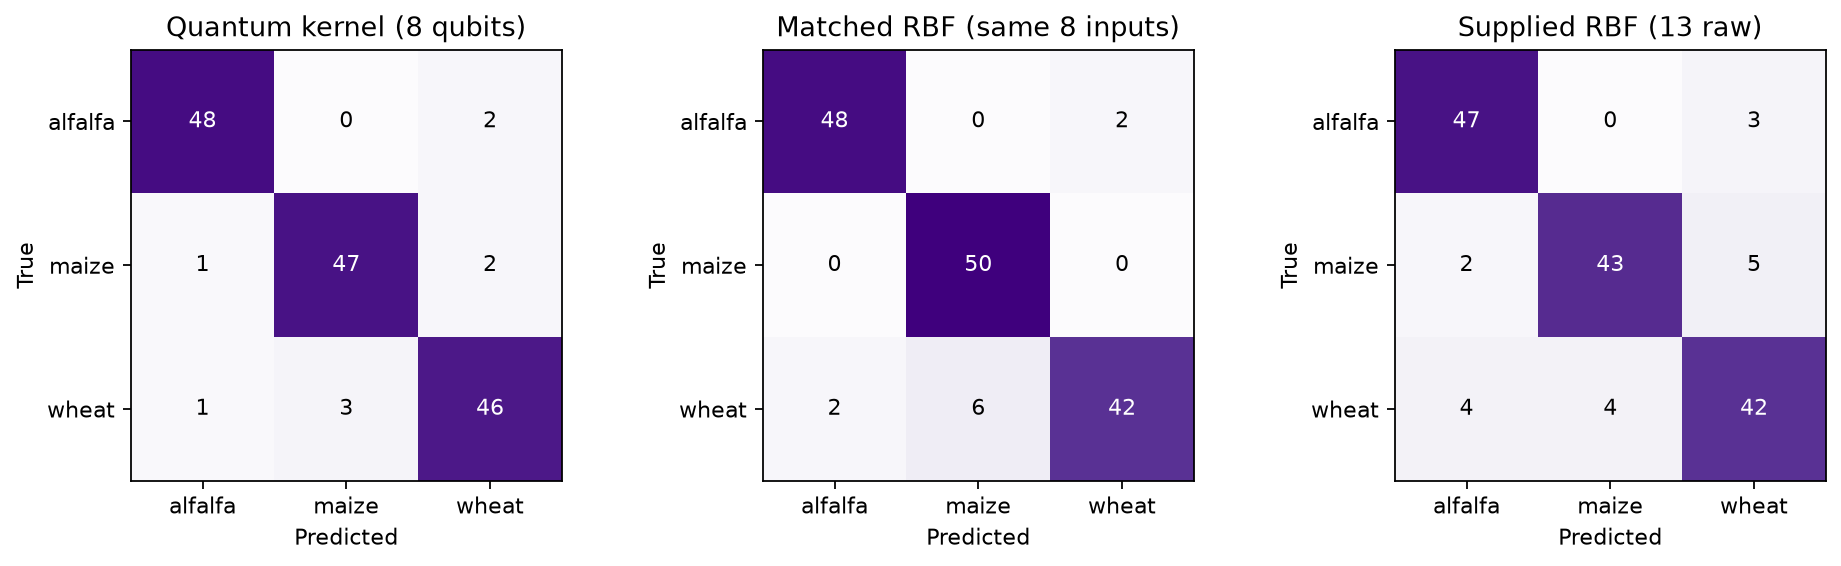

In [10]:
import os, subprocess
from IPython.display import Image
if os.environ.get('RERUN_STUDY', '1') != '0':
    subprocess.run([sys.executable, '-m', 'challenge.qk_run'], cwd=ROOT, check=True)
subprocess.run([sys.executable, '-m', 'challenge.qk_figures'], cwd=ROOT, check=True)
QK = ROOT / 'outputs/qk'
s = json.loads((QK / 'summary.json').read_text())
print('Selected quantum kernel:', s['final_config'], '| matched RBF:', s['matched_rbf_config'])
print('Tuning:', s['tuning'])

# Mean +/- SD over seeds 0/1/2 for every model, with per-class precision/recall and runtime.
rows = []
for m in ['quantum_kernel', 'no_entanglement', 'matched_rbf', 'reference']:
    r = [x for x in s['runs'] if x['model'] == m]
    f1 = np.array([x['metrics']['macro_f1'] for x in r]); acc = np.array([x['metrics']['accuracy'] for x in r])
    row = {'model': m, 'macro_f1': f'{f1.mean():.4f} ± {f1.std():.4f}', 'accuracy': f'{acc.mean():.4f} ± {acc.std():.4f}'}
    for k, c in enumerate(LABELS):
        row[f'precision_{c}'] = round(np.mean([x['metrics']['precision'][k] for x in r]), 3)
        row[f'recall_{c}'] = round(np.mean([x['metrics']['recall'][k] for x in r]), 3)
    row['fit_s'] = round(np.mean([x['fit_seconds'] for x in r]), 3); row['predict_150_s'] = round(np.mean([x['predict_150_seconds'] for x in r]), 3)
    rows.append(row)
display(pd.DataFrame(rows).set_index('model'))
display(pd.DataFrame({x['model']: x['resources'] for x in s['runs'] if x['seed'] == 0}).fillna('–'))
display(pd.DataFrame(s['comparisons']).T)
display(Image(filename=str(QK / 'fig1_scores.png')))
display(Image(filename=str(QK / 'fig2_confusion.png')))

## 6. Ablations and training size

**Ablations and data size.** Each variant is tuned on its own grid with the same rule. Filled markers are the tuned best; open diamonds are the mean over the whole grid, a measure of how easy the variant is to tune. The learning curve refits the encoder and re-tunes both models at 100/200/600/914 training fields (the supplied nested subsets). The final check confirms that, without entanglement, the circuit's kernel equals the classical closed form ∏cos²(a·Δx) to machine precision.

,best_f1,grid_mean_f1,configs
entangled_reps1,0.940000,0.905394,80.0
no_entanglement,0.939988,0.911304,20.0
entangled_reps2,0.933385,0.891427,80.0
entangled_reps3,0.926418,0.899652,80.0
matched_rbf,0.932338,0.904159,80.0


,quantum_kernel,matched_rbf,reference
size,,,
100,0.878010,0.889062,0.859069
200,0.919786,0.912606,0.859253
600,0.932632,0.919740,0.886459
914,0.940000,0.932338,0.879740


max |K_circuit - prod cos^2(a dx)| without entanglement: 4.773959005888173e-15


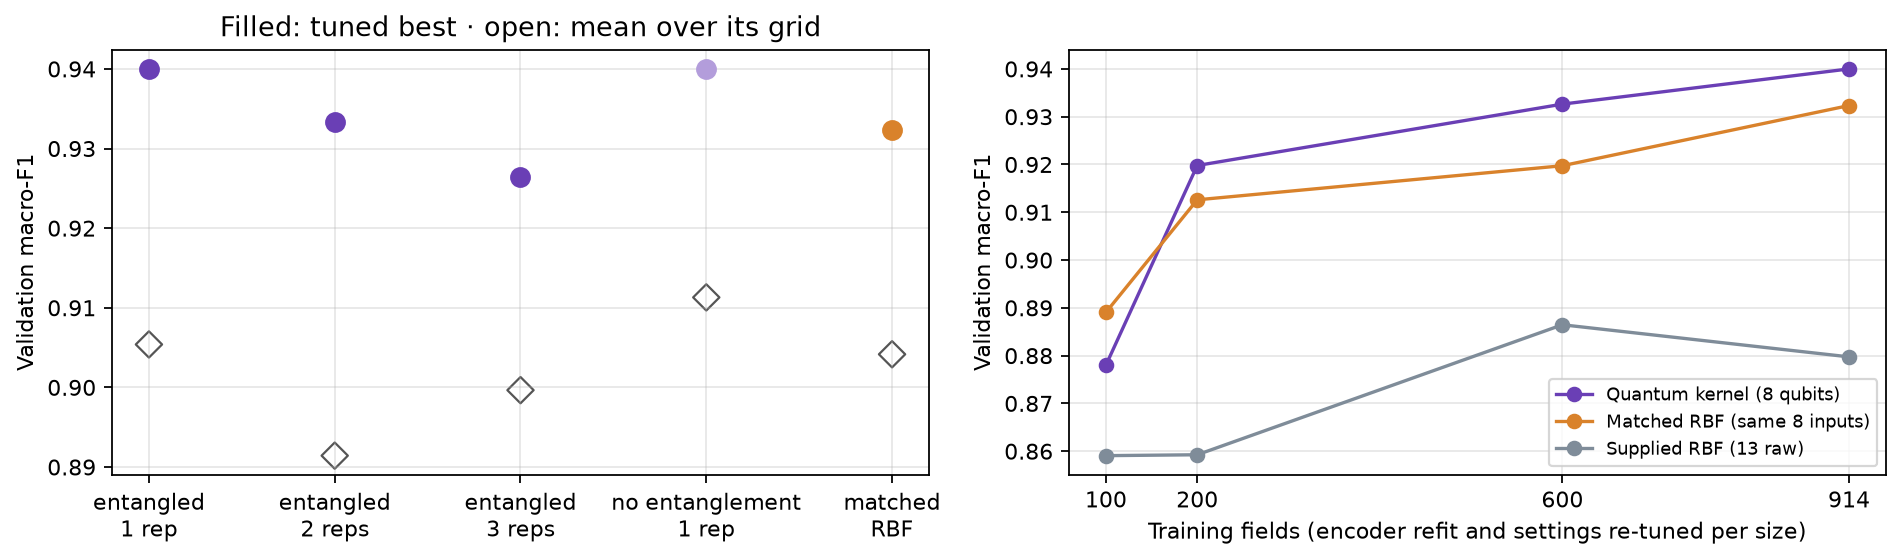

In [11]:
display(pd.DataFrame({k: {'best_f1': v['best']['f1'], 'grid_mean_f1': v['grid_mean_f1'], 'configs': v['configs']} for k, v in s['ablation'].items()}).T)
display(pd.DataFrame(s['learning_curve']).set_index('size'))
print('max |K_circuit - prod cos^2(a dx)| without entanglement:', s['closed_form_error'])
display(Image(filename=str(QK / 'fig3_ablation_learning.png')))

In [12]:
# Submission interface check: the organizers' entry point reproduces the stored validation predictions.
from time import perf_counter
from challenge.submission import Submission
t = perf_counter()
sub = Submission().fit(train[features].to_numpy(), train.target.to_numpy(), seed=0)
pred = sub.predict(validation[features].to_numpy())
print(f'Submission fit+predict: {perf_counter() - t:.1f} s (budget 35 min per seed)')
stored = pd.read_csv(QK / 'validation_predictions.csv')
assert (pred == stored.quantum_kernel.to_numpy()).all()
print('Validation:', {k: v for k, v in score(validation.target, pred, LABELS).items() if k in ['macro_f1', 'accuracy']})
test_pred = pd.read_csv(QK / 'test_predictions.csv')
assert (sub.predict(tables['test'][features].to_numpy()) == test_pred.prediction.to_numpy()).all()
print('Test predictions (outputs/qk/test_predictions.csv):', test_pred.prediction.value_counts().to_dict())

Submission fit+predict: 2.5 s (budget 35 min per seed)
Validation: {'macro_f1': 0.94, 'accuracy': 0.94}


Test predictions (outputs/qk/test_predictions.csv): {'wheat': 100, 'maize': 70, 'alfalfa': 51}


## 7. Optional IBM inference (hardware bonus): quantum-kernel rows on a real device

No hardware training. The SVM is fitted locally on the exact kernel. For a few validation fields, the device estimates one kernel row `K(x, sv) = P(00000000)` of the compute–uncompute circuit `U(sv)† U(x)|0⟩` for each of the 190 support vectors, plus one self-pair circuit `U(x)† U(x)` (ideal value 1) that measures the global shrink factor λ. A barrier keeps the transpiler from cancelling that circuit. Corrected kernel: `(K_hw − (1−λ)/256) / λ`. The locally fitted SVM then classifies each field from its hardware kernel row.

Commands (credentials come from your saved Qiskit account or `QISKIT_IBM_TOKEN`; `--approve` is required because device time is spent):

```bash
python -m challenge.qk_hardware submit --backend ibm_kingston --fields 0 1 28 --shots 1000 --twirl --approve
python -m challenge.qk_hardware analyze --job <JOB_ID>
python -m challenge.qk_hardware shots      # local finite-shot study on all 150 validation fields
```

Fields 0, 1 and 28 are the first validation field of each crop (wheat, maize, alfalfa), fixed before any device run. The cell below only reads stored reports; set `HARDWARE_ENABLED = True` to submit a new job.

,report_dc01gtinj2vs73dda5l0
backend,ibm_kingston
job_id,dc01gtinj2vs73dda5l0
twirling,False
circuits,191
shots,1000
isa_depth_max,107
isa_two_qubit_max,26
true_labels,[wheat]
predicted_exact,[wheat]
predicted_ideal_shots,[wheat]


,report_dc01ihanj2vs73dda82g
backend,ibm_kingston
job_id,dc01ihanj2vs73dda82g
twirling,True
circuits,573
shots,1000
isa_depth_max,125
isa_two_qubit_max,28
true_labels,"[wheat, maize, alfalfa]"
predicted_exact,"[wheat, maize, alfalfa]"
predicted_ideal_shots,"[wheat, wheat, alfalfa]"


model,hardware_like,ideal
shots,,
1000,0.441600,0.508696
4000,0.536297,0.581390
10000,0.591180,0.680157
100000,0.790312,0.851842


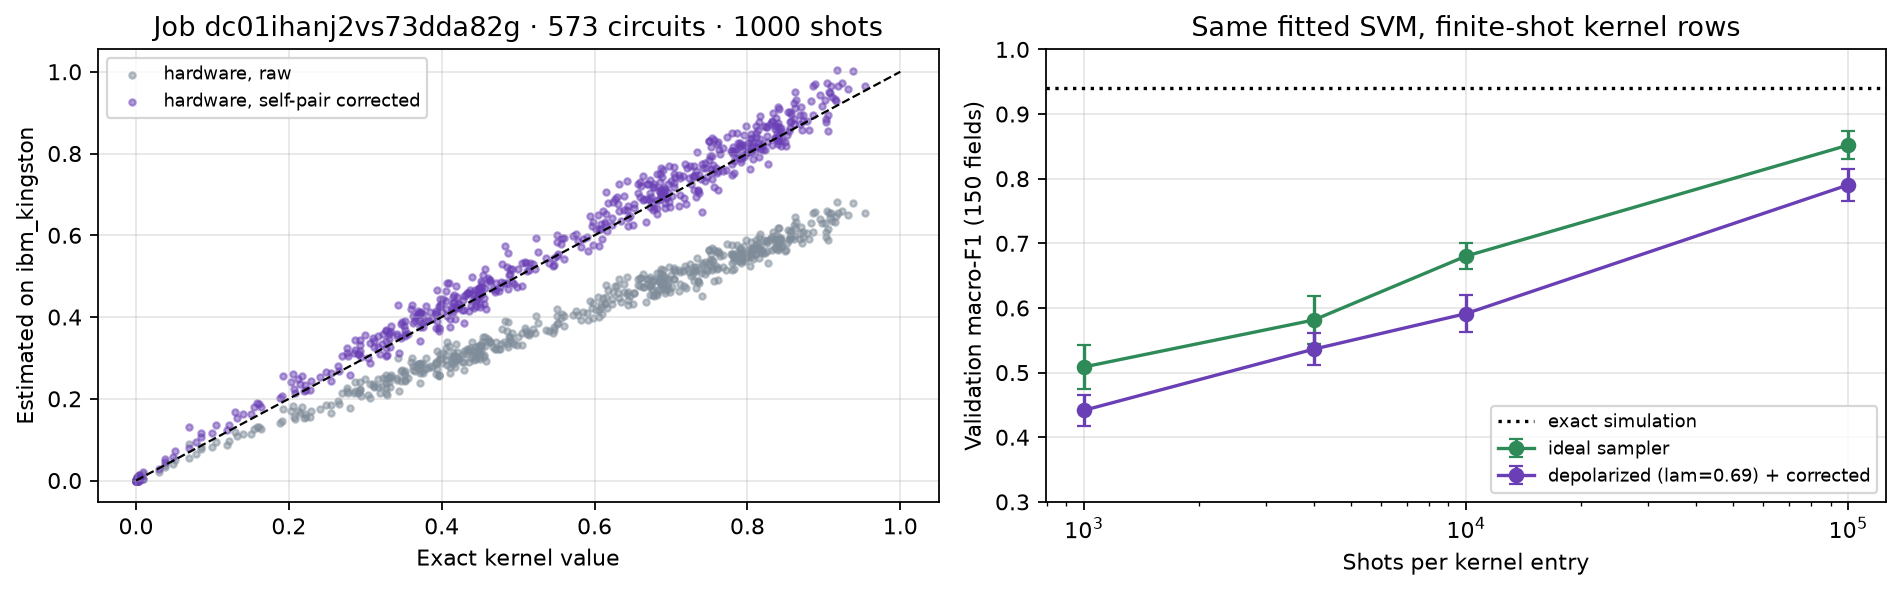

In [13]:
HARDWARE_ENABLED = False  # True submits a real IBM job and spends device time
if HARDWARE_ENABLED:
    subprocess.run([sys.executable, '-m', 'challenge.qk_hardware', 'submit', '--backend', 'ibm_kingston',
                    '--fields', '0', '1', '28', '--shots', '1000', '--twirl', '--approve'], cwd=ROOT, check=True)
HW = ROOT / 'outputs/qk/hardware'
keys = ['backend', 'job_id', 'twirling', 'circuits', 'shots', 'isa_depth_max', 'isa_two_qubit_max', 'true_labels', 'predicted_exact',
        'predicted_ideal_shots', 'predicted_hardware_raw', 'predicted_hardware_corrected', 'self_pair_fidelity', 'kernel_mae', 'usage_seconds']
for f in sorted(HW.glob('report_*.json')):
    r = json.loads(f.read_text()); display(pd.Series({k: r.get(k, False) for k in keys}, name=f.stem).to_frame())
display(pd.DataFrame(json.loads((HW / 'shots_study.json').read_text())['rows']).pivot(index='shots', columns='model', values='macro_f1_mean'))
display(Image(filename=str(ROOT / 'outputs/qk/fig4_hardware.png')))

## 8. Findings, claims and limitations

**Answer to the focused question: no.** On this data, the entangling part of the feature map adds nothing measurable beyond a classical RBF kernel on the same inputs.

- **Quantum kernel vs supplied reference:** +0.060 (95% CI +0.026 to +0.109). The matched RBF gains almost as much, +0.053 (95% CI +0.019 to +0.091). **The gain comes from the shared 8-component encoder and bandwidth tuning, not from the circuit.**
- **Quantum kernel vs matched RBF:** +0.008 (95% CI -0.026 to +0.045), 7 of 150 fields differ. A tie.
- **Entanglement:** tuning selected the weakest entangling strength on the grid (γ = 0.01). Removing every RZZ changes 2 fields: -0.000 (95% CI -0.002 to +0.003). Without entanglement, the kernel equals the classical closed form ∏cos²(a·Δx) (max error 4.8e-15).
- **Depth:** 1/2/3 repetitions reach 0.940 / 0.933 / 0.926. Grid means fall (0.905 → 0.891 → 0.900): deeper circuits are harder to tune, not better.
- **Training size:** the quantum kernel and matched RBF stay within about 0.013 of each other from 100 to 914 fields; no size shows a separation (single runs, no interval per size).
- **Hardware (bonus):** on ibm_kingston, self-pair-corrected kernel entries match exact values about as well as an ideal 1000-shot sampler. Even so, the SVM fitted on the exact kernel needs very precise kernel rows: an ideal sampler reaches only about 0.85 macro-F1 at 100,000 shots per entry. Device inference of this classifier is therefore limited by shot count before device noise.

**What we do not claim:** no quantum advantage; no speed advantage (simulated quantum fit ≈ 3 s vs 0.07 s for the RBF); no hardware accuracy estimate (3 fields only); nothing beyond 914 training rows.

**Limitations:** the 150 validation fields also chose the settings, so absolute scores are optimistic (1 field ≈ 0.007 macro-F1). Paired intervals of about ±0.035 cannot resolve differences of a few fields. The test class mix (42/77/102) differs from validation (50/50/50). All models are deterministic, so seeds 0/1/2 measure no training variability (SD = 0). Before the final grids, an exploratory pass tried about 80 quantum and 20 RBF configurations; the reported grids are equal (80 vs 80).

## Which file should you change?

| File | How it works / when to edit |
| --- | --- |
| [`data.py`](../challenge/data.py) | Loads CSV/PCA files and checks hashes, schemas and split IDs. Keep these checks; put new train-fitted preprocessing in your experiment. |
| [`models.py`](../challenge/models.py) | Converts inputs to angles, builds the circuit, trains the QNN/control and returns predictions/resources. Edit encoding, architecture, optimizer or control here; you may replace either model. |
| [`classical.py`](../challenge/classical.py) | Builds StandardScaler → RBF-SVM from `configs/reference.json`. Preserve the supplied baseline; add comparisons separately. |
| [`metrics.py`](../challenge/metrics.py) | Scores every declared class and checks probability arrays. Reuse it unchanged for comparable metrics. |
| [`submission.py`](../challenge/submission.py) | Exposes the starter as `Submission`. Replace it with your final model, keeping `fit(X_train, y_train, seed)` and `predict(X)`; document preprocessing/input shape. |
| [`coverage.py`](../challenge/coverage.py) | Selects training subsets, fits preprocessing/models over three seeds and compares validation predictions by spatial bootstrap. Update model construction to benchmark your replacement. |
| [`hardware.py`](../challenge/hardware.py) | Binds trained weights, transpiles for the chosen backend and submits optional inference. Edit only if you need a device demonstration for a different model. |
| [`__init__.py`](../challenge/__init__.py) | Marks `challenge` as a Python package; no changes are needed. |

`configs/pilot.json` records starter settings; it is not read automatically. Change constructor arguments here and in the coverage/submission adapters as appropriate. If changing the input dimension, also update the model's four-input assumptions and its control. Restart the kernel after editing imported Python files, then run all cells.

For API details: [Qiskit functional circuit ansatz](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.real_amplitudes), [QNN classifier tutorial](https://stfc.github.io/qiskit-machine-learning/tutorials/02_neural_network_classifier_and_regressor.html), [exact sampler](https://stfc.github.io/qiskit-machine-learning/stubs/qiskit_machine_learning.primitives.QMLSampler.html). Use the pinned versions in `requirements.txt`.

**Finish:** run your selected model and control with seeds 0/1/2 on all training fields; report validation metrics, resource costs and limitations. Submit the runnable implementation and three to five slides as described in the [student brief](../Student_Challenge_Brief.pdf) and [README](../README.md).